# 02 Data collection

Stage 2 of the project asks which data can answer *"may I park here, and until when?"*, how we get
it, and whether we can trust it to stay put while we work on it. This notebook is the team's
walkthrough of that stage: the sources we use, what the raw data looks like when it arrives, the
one trap in reading it back, and the source we measured and rejected.

**How it is built.** Fetching is done by [`pipeline/fetch.py`](../pipeline/fetch.py), the same
code that makes the project's snapshots. This notebook calls it and looks at the result; it does
not keep its own downloader.

**This notebook reads live data.** Unlike the other stage notebooks, it downloads from the city's
servers when it runs, so its numbers are *today's*. The outputs saved with it record the day it
was last run, printed in the first cell. Everything after this stage works from the committed
snapshot instead, which is the point of section 7.

**Run it** with the "Python (parkkiko)" kernel and a network connection, then *Restart & Run All*.
It takes about half a minute. Nothing is written into the repository.

**Contents**
1. The source: Helsinki's parking register
2. Fetching it
3. What one raw record looks like
4. How complete the raw fields are
5. Reading it back: the coordinate trap
6. The second source: districts
7. The third source: the holiday calendar
8. Why we freeze a snapshot
9. A source we measured and rejected: temporary traffic arrangements
10. Other sources we considered
11. What this stage hands on
12. Reflection on the stage

In [1]:
import json
import os
import sys
import tempfile
import time
from datetime import date
from pathlib import Path

# Run from the repository root, so paths mean what they mean in pipeline/
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "pipeline")

import geopandas as gpd
import pandas as pd

import export_holidays
import fetch
import process

print(f"Run on {date.today().isoformat()}")

Run on 2026-10-23


## 1. The source: Helsinki's parking register

The City of Helsinki publishes its street parking register as open data: every parking area as a
polygon drawn along the kerb, with its class, the type of space and the rule written out as
text. It is served by the city's map server over **WFS** (Web Feature Service), a standard
protocol for asking a map server for features as data rather than as a picture.

| | |
|---|---|
| Server | `kartta.hel.fi/ws/geoserver/avoindata/wfs` |
| Layer | `avoindata:Pysakointipaikat_alue` |
| Licence | Creative Commons Attribution 4.0 |
| Access | no account, key or registration |

A request is a plain URL. This is the one `fetch.py` sends, first page:

In [2]:
layer, crs = fetch.LAYERS["parking_areas_3879"]
print(f"{fetch.WFS}?service=WFS&version=2.0.0&request=GetFeature&typeNames={layer}"
      f"&outputFormat=application/json&srsName={crs}&count={fetch.PAGE}&startIndex=0")

https://kartta.hel.fi/ws/geoserver/avoindata/wfs?service=WFS&version=2.0.0&request=GetFeature&typeNames=avoindata:Pysakointipaikat_alue&outputFormat=application/json&srsName=EPSG:3879&count=20000&startIndex=0


We ask for coordinates in **EPSG:3879**, the Finnish metric system for Helsinki, so that distances
come out in metres. The app needs GPS coordinates instead, and the pipeline converts once, when it
writes the app's file.

## 2. Fetching it

`fetch_layer` sends that request and follows the server's paging until it has every feature.

In [3]:
started = time.perf_counter()
fc = fetch.fetch_layer(layer, crs)
seconds = time.perf_counter() - started

size_mb = len(json.dumps(fc, ensure_ascii=False).encode()) / 1e6
print(f"{len(fc['features']):,} parking areas, {size_mb:.1f} MB as GeoJSON, {seconds:.1f} s")

8,754 parking areas, 7.3 MB as GeoJSON, 1.7 s


The whole register is a few megabytes and arrives in seconds. That one measurement shaped the
project: there is no database, no object store and no backend, because the data fits in a git
repository and, once converted, in a browser.

## 3. What one raw record looks like

Each feature carries a geometry and a set of properties. Here are the properties of one area,
exactly as the server sent them:

In [4]:
fc["features"][0]["properties"]

{'id': 8001,
 'luokka': 6,
 'luokka_nimi': 'Maksullinen ilman asukas-/yritystunnusta. Maksullisuusajat vaihtelevat kohteesta riippuen.',
 'tyyppi': None,
 'kausi': None,
 'asukaspysakointitunnus': 'F',
 'paikan_asento': 'kadunsuuntainen',
 'voimassaolo': '9-21',
 'kesto': None,
 'pinta_ala': 41.91,
 'paikat_des': 3.4925,
 'paikat_ala': 3,
 'lisatieto': None,
 'pysayttamiskielto': '',
 'paivitetty_tietopalveluun': '2026-10-22',
 'datanomistaja': 'KYMP MAKA LIKE'}

The fields that carry the rule are all in Finnish and all text:

| Field | Meaning | Example |
|---|---|---|
| `luokka` | parking class, a number | `6` |
| `luokka_nimi` | the class's name | *Maksullinen ilman asukas- tai yrityspysäköintitunnusta* |
| `tyyppi` | the type of space, when special | `Taxi`, `Pysäköintikielto` (no parking) |
| `voimassaolo` | the hours the rule applies | `9-21, (9-18)` |
| `kesto` | the time limit | `4 h` |
| `kausi` | the season | `1.4. - 31.10.` |
| `lisatieto` | anything else, free text | a sign code, or a condition in prose |

Nothing here is ready to use. `9-21, (9-18)` means Monday to Friday 9 to 21 and Saturday 9 to 18,
but only a person who knows Finnish parking signs can tell. Turning these strings into rules is
stage 3, in [03 preprocessing](03_preprocessing.ipynb).

### Fields we do not use

The record also carries fields the pipeline drops. Before dropping data, look at it:

In [5]:
rule_fields = ["luokka", "luokka_nimi", "tyyppi", "voimassaolo", "kesto", "kausi", "lisatieto"]
unused = [c for c in fc["features"][0]["properties"] if c not in ["id", *rule_fields]]
table = gpd.GeoDataFrame.from_features(fc["features"])[unused]
stated_unused = table.apply(lambda col: col.notna() & (col.astype(str).str.strip() != ""))
pd.DataFrame({
    "areas stating it": stated_unused.sum(),
    "distinct values": [table.loc[stated_unused[c], c].nunique() for c in unused],
    "most common": [table.loc[stated_unused[c], c].astype(str).value_counts().index[0]
                    if stated_unused[c].any() else "" for c in unused],
})

,areas stating it,distinct values,most common
asukaspysakointitunnus,5530,30,N
paikan_asento,8184,8,kadunsuuntainen
pinta_ala,8754,6188,12.0
paikat_des,8456,5290,0.0
paikat_ala,8456,57,0.0
pysayttamiskielto,0,0,
paivitetty_tietopalveluun,8754,1,2026-10-22
datanomistaja,8754,1,KYMP MAKA LIKE


In [6]:
spaces = pd.to_numeric(table["paikat_ala"])
print(f"{spaces.sum():,.0f} parking spaces in all, in {(spaces > 0).sum():,} of the areas")

37,544 parking spaces in all, in 6,800 of the areas


| Field | What it is | Why it matters |
|---|---|---|
| `paikat_ala` | number of parking spaces in the area (`paikat_des` is a fractional estimate) | the denominator for fines per space, and "3 spaces here" in the app |
| `asukaspysakointitunnus` | the resident-permit zone letter | permit holders are exempt from many rules: the key to serving residents, not only visitors |
| `paikan_asento` | how cars stand: along the kerb, at right angles, diagonally | helps a driver recognise the bay on the street |
| `pinta_ala` | the polygon's area in m² | duplicates what the geometry gives us |
| `pysayttamiskielto` | meant to mark a no-stopping zone | empty in every area; no-stopping arrives through `tyyppi` instead |
| `paivitetty_tietopalveluun`, `datanomistaja` | export date and data owner | one value for every area, so they cannot show which areas changed |

We left all of them out because our target user is a visitor without a permit, and nothing in the
first version of the app needed them. The first three are the most valuable data we are not using.

## 4. How complete the raw fields are

Before parsing anything: how often does each field say anything at all?

In [7]:
raw = gpd.GeoDataFrame.from_features(fc["features"])
fields = ["luokka", "luokka_nimi", "tyyppi", "voimassaolo", "kesto", "kausi", "lisatieto"]
stated = raw[fields].apply(lambda col: col.notna() & (col.astype(str).str.strip() != ""))
pd.DataFrame({"areas stating it": stated.sum(), "share": (stated.mean() * 100).round(1)})

,areas stating it,share
luokka,8411,96.1
luokka_nimi,6828,78.0
tyyppi,1888,21.6
voimassaolo,5832,66.6
kesto,2507,28.6
kausi,480,5.5
lisatieto,1761,20.1


Most areas state a class, but the hours are missing from about a third and the time limit from
most. Some of that is fine: a ban or a reserved bay applies at every hour and needs none. Some of
it is the gap this project is about, and stage 3 tells the two apart.

## 5. Reading it back: the coordinate trap

`fetch.py` saves each layer as a GeoJSON file in `data/raw/<date>/`, and the pipeline reads it
back from there. This is where we caused ourselves the project's most instructive bug.

The server's response *does* declare its coordinate system:

In [8]:
probe = (f"{fetch.WFS}?service=WFS&version=2.0.0&request=GetFeature&typeNames={layer}"
         f"&outputFormat=application/json&srsName={crs}&count=1")
import urllib.request
print(json.load(urllib.request.urlopen(probe, timeout=60))["crs"])

{'type': 'name', 'properties': {'name': 'urn:ogc:def:crs:EPSG::3879'}}


But `fetch_layer` keeps only the features, so the saved file carries no declaration, and a GeoJSON
file without one is defined to be WGS84, plain latitude and longitude. Save it the way `fetch.py`
does, read it back the obvious way, and look at what geopandas believes:

In [9]:
snapshot = Path(tempfile.mkdtemp()) / "parking_areas_3879.geojson"   # outside the repository
snapshot.write_text(json.dumps(fc, ensure_ascii=False))                # exactly what fetch.py saves

naive = gpd.read_file(snapshot)
print("declared:", naive.crs)
print("coordinates:", naive.total_bounds.round(0))

declared: EPSG:4326
coordinates: [25491363.  6670506. 25509485.  6684775.]


It claims degrees, and holds numbers in the millions: metres, labelled as degrees. Nothing
fails. To see the damage, ask the obvious question, *which district is each area in?*, using
districts fetched in real GPS coordinates:

In [10]:
districts_gps = gpd.GeoDataFrame.from_features(
    fetch.fetch_layer("avoindata:Piirijako_peruspiiri", "CRS:84")["features"], crs=4326)

wrong = gpd.sjoin(naive[["geometry"]], districts_gps[["nimi_fi", "geometry"]], predicate="intersects")
print(f"areas matched to a district, naive read: {wrong.index.nunique():,} of {len(naive):,}")

areas matched to a district, naive read: 0 of 8,754


Zero, and no error. We noticed only because zero was implausible. The fix is one line, and every
read of a snapshot in the pipeline goes through it: `read_metric` in
[`pipeline/process.py`](../pipeline/process.py) asserts the coordinate system the file really
holds.

In [11]:
areas = process.read_metric(snapshot)
right = gpd.sjoin(areas[["geometry"]], districts_gps.to_crs(areas.crs)[["nimi_fi", "geometry"]],
                  predicate="intersects")
print("declared:", areas.crs.name)
print(f"areas matched to a district, read_metric: {right.index.nunique():,} of {len(areas):,}")

declared: EUREF-FIN / GK25FIN
areas matched to a district, read_metric: 8,754 of 8,754


Asserting a coordinate system is not the same as verifying it, so the pipeline also checks the
numbers before it writes anything: `process.check` refuses coordinates that are not metres around
Helsinki. It passes on today's data:

In [12]:
process.check(areas)
print("check passed")

check passed


## 6. The second source: districts

Helsinki's 34 basic districts (`avoindata:Piirijako_peruspiiri`), same server, same licence. We
use them to say where an area is, to measure coverage per district, and to hold out whole
districts when validating the learning stage. We chose the 34 basic districts over the 148
sub-areas because they are big enough to hold out and named after places people recognise.

34 districts

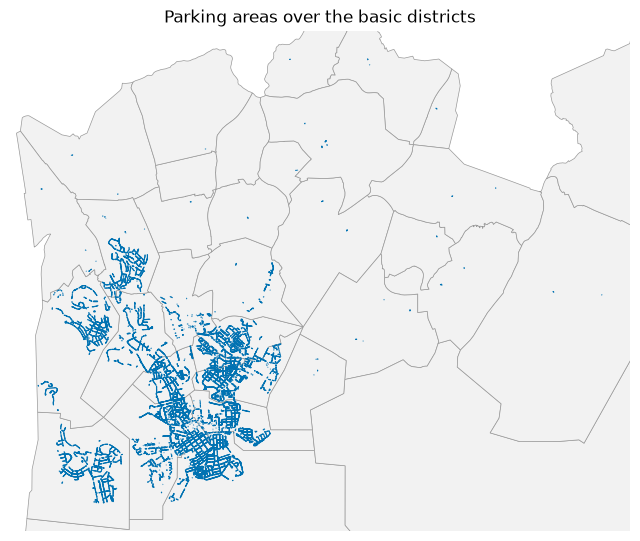

In [13]:
districts = gpd.GeoDataFrame.from_features(
    fetch.fetch_layer(*fetch.LAYERS["districts_3879"])["features"], crs=3879)
print(f"{len(districts)} districts")

ax = districts.plot(color="#f2f2f2", edgecolor="#999999", linewidth=0.5, figsize=(8, 8))
areas.plot(ax=ax, color="#0072B2", edgecolor="#0072B2", linewidth=0.8)
# Several districts are mostly sea; frame the map on the parking areas instead
minx, miny, maxx, maxy = areas.total_bounds
pad = 0.05 * max(maxx - minx, maxy - miny)
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title("Parking areas over the basic districts")
ax.set_axis_off();

Already visible before any analysis: the register covers the centre densely and the suburbs
barely. Stage 4 measures that, in [04 exploration](04_exploration.ipynb).

## 7. The third source: the holiday calendar

A Finnish parking sign states up to three windows: weekdays, Saturday in brackets, Sunday. On a
public holiday the Sunday window applies, and on the day before one the Saturday window. The
register does not say which days those are, so the third source is a calendar: the `holidays`
package, turned into a list of dates by
[`pipeline/export_holidays.py`](../pipeline/export_holidays.py).

In [14]:
calendar = export_holidays.build()
days = pd.DataFrame.from_dict(calendar["days"], orient="index")
print(f"covers {calendar['years'][0]}-{calendar['years'][1]}: {len(days)} dates whose window is not their weekday")
days.head(8)

covers 2026-2028: 61 dates whose window is not their weekday


,window,name,status,reason
2026-01-01,sun,New Year's Day,NaN,NaN
2026-01-05,sat,day before Epiphany,NaN,NaN
2026-01-06,sun,Epiphany,NaN,NaN
2026-04-02,sat,day before Good Friday,NaN,NaN
2026-04-03,sun,Good Friday,NaN,NaN
2026-04-06,sun,Easter Monday,NaN,NaN
2026-04-30,sat,day before May Day,NaN,NaN
2026-05-01,sun,May Day,NaN,NaN


Two days are flagged rather than resolved: Christmas Eve and Midsummer Eve. The calendar calls
them holidays, and we have not confirmed that the city's parking rules do. Reading them as
Sundays would tell a driver parking is free when it may be paid, so they, and the days whose
window rests on them, are marked uncertain and the app says *check the sign*:

In [15]:
days[days["status"] == "uncertain"][["window", "name", "reason"]]

,window,name,reason
2026-06-18,sat,day before Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."
2026-06-19,sun,Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."
2026-12-23,sat,day before Christmas Eve,"rests on Christmas Eve, which the calendar cal..."
2026-12-24,sun,Christmas Eve,"rests on Christmas Eve, which the calendar cal..."
2027-06-24,sat,day before Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."
2027-06-25,sun,Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."
2027-12-23,sat,day before Christmas Eve,"rests on Christmas Eve, which the calendar cal..."
2027-12-24,sun,Christmas Eve,"rests on Christmas Eve, which the calendar cal..."
2028-06-22,sat,day before Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."
2028-06-23,sun,Midsummer Eve,"rests on Midsummer Eve, which the calendar cal..."


## 8. Why we freeze a snapshot

The register is live: the city edits it whenever a sign changes. If each of us downloaded it on a
different day, we would be analysing different data without knowing it. So `fetch.py` saves a
dated snapshot, the pipeline processes the newest one into
`data/processed/parking_rules.parquet`, and that file is **committed to git**, so the whole team,
the report and the app work from one identical copy.

Has the register changed since our snapshot? Compare today's download with it, area by area:

In [16]:
committed = gpd.read_parquet("data/processed/parking_rules.parquet")
live = raw.assign(id=raw["id"].astype(int)).set_index("id")
ours = committed.set_index("id")

added, removed = live.index.difference(ours.index), ours.index.difference(live.index)
both = live.index.intersection(ours.index)

def differs(a, b):
    """A real change, not a difference in how missing is written."""
    return ~((a.isna() & b.isna()) | (a == b).fillna(False))

changed = pd.Series({f: int(differs(live.loc[both, f], ours.loc[both, f]).sum()) for f in fields})
print(f"snapshot: {len(ours):,} areas | today: {len(live):,} | added {len(added)} | removed {len(removed)}")
changed.rename("areas whose field changed").to_frame()

snapshot: 8,754 areas | today: 8,754 | added 0 | removed 0


,areas whose field changed
luokka,0
luokka_nimi,0
tyyppi,0
voimassaolo,0
kesto,0
kausi,0
lisatieto,0


If this ever shows changes, nothing downstream moves on its own: the committed snapshot stays the
team's shared truth until someone reruns `fetch.py` and `process.py` and commits the result,
which updates the report's figures and the app's data together.

## 9. A source we measured and rejected: temporary traffic arrangements

The canvas planned a second layer: live roadworks, so the app could say a street's spaces are
closed. The city publishes `avoindata:Tilapainen_liikennejarjestely_alue`, *temporary traffic
arrangements*, which sounded like exactly that. We built the join and measured what it gave us
before trusting the name. The same measurement, on today's data:

In [17]:
works = gpd.GeoDataFrame.from_features(
    fetch.fetch_layer("avoindata:Tilapainen_liikennejarjestely_alue", "EPSG:3879")["features"], crs=3879)
starts = pd.to_datetime(works["liikennejarjestely_alkaa"])
ends = pd.to_datetime(works["liikennejarjestely_paattyy"])
days_long = (ends - starts).dt.days

print(f"{len(works)} arrangements")
print(f"duration: median {days_long.median():.0f} days, longest {days_long.max():,.0f} days")
print(f"status says ongoing: {(works['status'] == 'Käynnissä').sum()}, "
      f"of which already ended: {((works['status'] == 'Käynnissä') & (ends < pd.Timestamp.today())).sum()}")

292 arrangements
duration: median 711 days, longest 3,204 days
status says ongoing: 279, of which already ended: 50


"Temporary" means years: these are construction projects and event permits, not closures. Does an
overlap at least tell us a parking area is affected?

In [18]:
hits = gpd.sjoin(areas[["id", "geometry"]], works.assign(ends=ends)[["ends", "tyon_tarkoitus", "geometry"]],
                 predicate="intersects")
active = hits[hits["ends"] >= pd.Timestamp.today()]
about_parking = active[active["tyon_tarkoitus"].str.contains("pysäk", case=False, na=False)]

print(f"parking areas overlapping an arrangement: {hits['id'].nunique()}")
print(f"  of which overlapping one still running: {active['id'].nunique()}")
print(f"  of which one whose stated purpose mentions parking: {about_parking['id'].nunique()}")

parking areas overlapping an arrangement: 168
  of which overlapping one still running: 147
  of which one whose stated purpose mentions parking: 18


An overlap tells us a permit exists nearby, not that the spaces are gone. Marking an area
uncertain on that basis would be the same unfounded confidence the project exists to avoid, so we
dropped the layer. What the idea really needs is a feed of parking suspensions with real dates,
and Helsinki does not appear to publish one.

The lesson we took: **measure a dataset before trusting its name**, and do not include a source
because it exists.

## 10. Other sources we considered

Each is recorded, with its measurements, in [`docs/future-work.md`](../docs/future-work.md).

| Source | What we found | Decision |
|---|---|---|
| Parking fines, 2023 | 156,383 fines and 9,341 warnings, but dated only to the month and geocoded to street addresses, not to the parked car | not in the app; a street-level density layer is the stretch goal |
| Weather | nothing to join it to: the fines carry no day or hour | dropped |
| Traffic signs (Digiroad) | the sign a driver is fined by, with time panels and facing direction, but nothing links a sign to a parking area | future work, a real learning task |
| Crowdsourced rules | no user base during the course, and a wrong entry costs someone a fine | future work |

## 11. What this stage hands on

- **To preprocessing (stage 3):** a dated snapshot of 8,754 parking areas and 34 districts, read
  back with its real coordinate system, and a holiday calendar that knows which days it is unsure
  of.
- **To everyone:** one committed copy of the processed data, so the team, the report and the app
  cannot drift apart.
- **To the report:** the sources and their licence, the coordinate trap, and a rejected source
  with the measurement that rejected it.

## 12. Reflection on the stage

**What the canvas planned.** The canvas's data collection box listed three sources (the parking
register, live roadworks and closures, and the Finnish holiday calendar) and a data management
plan: scripted downloads saved as dated snapshots, all processing run on the snapshots, no
personal data stored.

**What worked.** The register is everything a course project hopes for: open, licensed for reuse,
no key, a few megabytes, seconds to download. The snapshot plan worked as intended and then some:
committing the *processed* snapshot to git, not only keeping raw ones, is what keeps the team, the
report and the app on one copy of the data, and section 8 can show that copy is still current. No
personal data entered the pipeline at any point.

**What did not, and why.** The roadworks layer did not describe what its name promised, and we
found out only after building the join, which is the wrong order. The coordinate trap cost us a
wrong answer that looked right: a spatial join that matched nothing and raised no error.

**What changed from the plan, and why.**
- *Roadworks dropped* after measurement (section 9), because an overlap could only make the app
  more confident than the data allows.
- *Districts added.* The canvas's own learning approach needed them, to hold out whole districts
  in validation and to report coverage fairly, but its data collection box did not list them.
- *The calendar became a generated file*, with the days we are unsure of marked rather than
  guessed, because a calendar package's idea of a holiday is not the city's parking rules.

**What we would do differently.**
- Measure a source's fitness *before* building anything on it.
- Keep the server's coordinate declaration in the saved snapshot. `fetch.py` still drops it and
  `read_metric` corrects for it on every read; storing it would remove the trap at its source.
- Profile every field before deciding what to keep. The fields we dropped (spaces per area,
  resident zone, bay orientation) turned out to answer questions we asked later.

**Possible future steps.** Use the fields we drop: spaces per area makes a fines-per-space layer
possible, and the resident zone opens the app to permit holders. Add Digiroad's traffic signs as a
second, independent source for the same rules. And because the pipeline depends only on a WFS
layer, any city publishing its parking register this way is one configuration away.

**Experience and technical implementation.** The technical core of this stage was small: WFS
requests with paging, GeoJSON, coordinate systems, dated snapshots. The lessons were not. Most of
the work was deciding what the data actually is: what a field means, which coordinate system it
really holds, and whether a dataset's name matches its content.

**Learning outcomes.**
- Data collection is provenance as much as download: where the data came from, under which
  licence, on which day, in which coordinate system.
- A file can state a fact about itself that is false, and libraries will believe it. Check the
  numbers, not only the metadata.
- Freezing a snapshot is what makes an analysis reproducible and a team consistent.

> *Each of us: add a line on what you personally took from this stage.*